#### Question 4 - Number of objects in `clutter.img`

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, exposure, feature

### LoG

single σ = 8    -> 393 blobs
single σ = 5    -> 770 blobs
range σ = 3–8   -> 1019 blobs


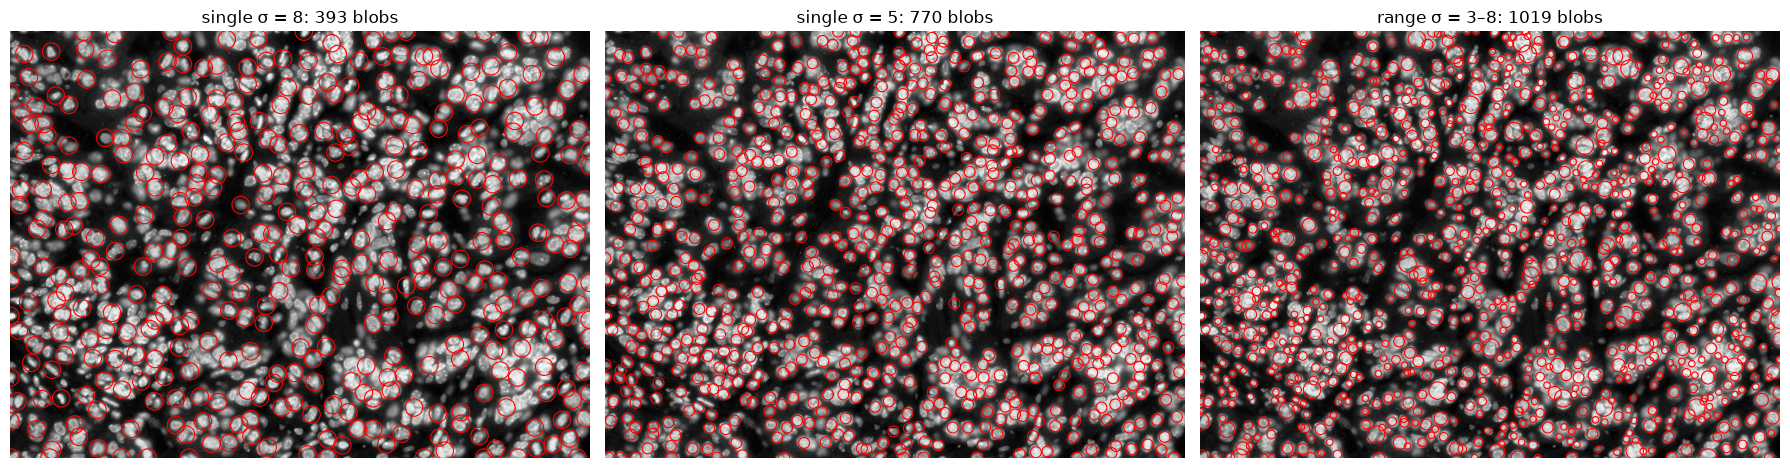

In [7]:
img = io.imread('clutter.png')
if img.ndim == 3:
    img = img[..., 0]
img = img.astype(float)
img = (img - img.min()) / (img.max() - img.min())        # scale to 0..1

# "Adaptive intensities" for Testing only (using CLAHE to brighten the nuclei for me to judge the output)
img_disp = exposure.equalize_adapthist(img, clip_limit=0.02)

def count_blobs(min_sigma, max_sigma, num_sigma, threshold):
    blobs = feature.blob_log(img, min_sigma=min_sigma, max_sigma=max_sigma,
                             num_sigma=num_sigma, threshold=threshold, overlap=0.5)
    return blobs        # each row: (row, col, sigma); radius ≈ sigma * sqrt(2)

# --- Single large sigma (your suggestion) vs. a range of sigmas ---
configs = {
    'single σ = 8':   dict(min_sigma=8, max_sigma=8, num_sigma=1, threshold=0.05),
    'single σ = 5':   dict(min_sigma=5, max_sigma=5, num_sigma=1, threshold=0.05),
    'range σ = 3–8':  dict(min_sigma=3, max_sigma=8, num_sigma=6, threshold=0.05),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, config) in zip(axes, configs.items()):
    blobs = count_blobs(**config)
    ax.imshow(img_disp, cmap='gray')
    for y, x, s in blobs:
        ax.add_patch(plt.Circle((x, y), s * np.sqrt(2), color='r', fill=False, lw=0.8))
    ax.set_title(f'{name}: {len(blobs)} blobs'); ax.axis('off')
    print(f'{name:<15} -> {len(blobs)} blobs')
plt.tight_layout(); plt.show()

### Watershed

Connected components only : 455
After watershed splitting : 785
Median nucleus area       : 176 px


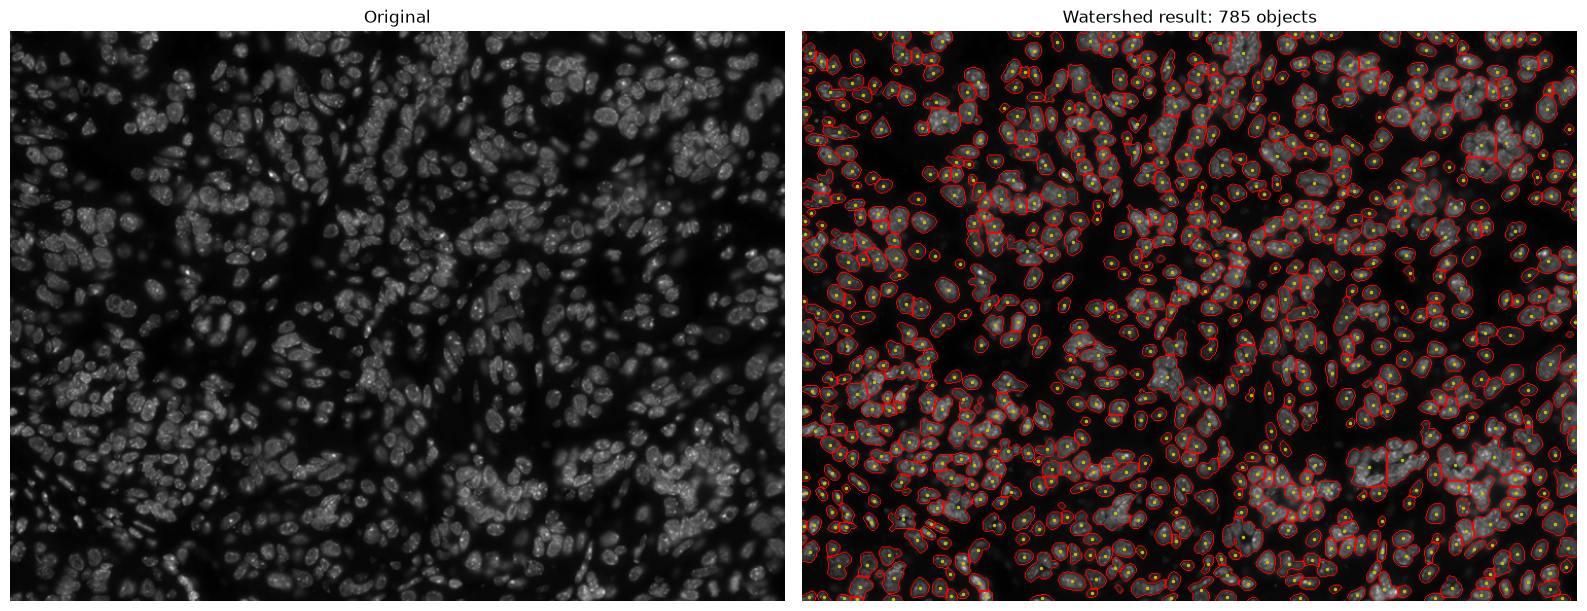

In [8]:
# --- Load as float grayscale ---
img = io.imread('clutter.png')
if img.ndim == 3:
    img = img[..., 0]
img = img.astype(float)

# 1. Smooth
sm = filters.gaussian(img, sigma=1.5, preserve_range=True)

# 2. Local threshold + low global floor
local_t = filters.threshold_local(sm, block_size=51, offset=0)   # block ~2-3x nucleus size
floor = 0.5 * filters.threshold_otsu(sm)
mask = (sm > local_t) & (sm > floor)

# 3. Clean up
mask = morphology.remove_small_objects(mask, max_size=20)
mask = ndi.binary_fill_holes(mask)
mask = morphology.opening(mask, morphology.disk(1))

# Baseline: plain connected components (will undercount because of touching nuclei)
cc_count = measure.label(mask, connectivity=2).max()

# 4. Distance transform + watershed
dist = ndi.distance_transform_edt(mask)
dist_s = filters.gaussian(dist, sigma=1.5)
coords = feature.peak_local_max(dist_s, min_distance=5, labels=measure.label(mask),
                                exclude_border=False)
markers = np.zeros(mask.shape, dtype=int)
markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
ws = segmentation.watershed(-dist_s, markers, mask=mask)

# 5. Count, ignoring tiny fragments
props = [r for r in measure.regionprops(ws) if r.area >= 30]
print(f"Connected components only : {cc_count}")
print(f"After watershed splitting : {len(props)}")
print(f"Median nucleus area       : {np.median([r.area for r in props]):.0f} px")

# 6. Visual check
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Original')
ax[1].imshow(segmentation.mark_boundaries(img / img.max(), ws, color=(1, 0, 0)))
ax[1].plot([r.centroid[1] for r in props], [r.centroid[0] for r in props], 'y.', ms=3)
ax[1].set_title(f'Watershed result: {len(props)} objects')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
blobs = count_blobs(min_sigma=3, max_sigma=8, num_sigma=6, threshold=0.05)

# How many blobs were detected at each scale?
sig, n = np.unique(blobs[:, 2], return_counts=True)
for s, c in zip(sig, n):
    print(f'σ = {s:.0f}: {c} blobs')

# Trying a narrower range
for lo, hi in [(4, 7), (4, 6), (5, 6)]:
    b = count_blobs(min_sigma=lo, max_sigma=hi, num_sigma=hi - lo + 1, threshold=0.05)
    print(f'σ {lo}–{hi}: {len(b)} blobs')

σ = 3: 825 blobs
σ = 4: 230 blobs
σ = 5: 135 blobs
σ = 6: 55 blobs
σ = 7: 27 blobs
σ = 8: 44 blobs
σ 4–7: 1003 blobs
σ 4–6: 1019 blobs
σ 5–6: 838 blobs


LoG blobs outside any watershed region (likely dim nuclei the mask missed): 201
Watershed regions with 0 blobs: -4
Watershed regions with exactly 1 blob: 574
Watershed regions with 2+ blobs: 215  (under-split clumps, or one nucleus double-detected)


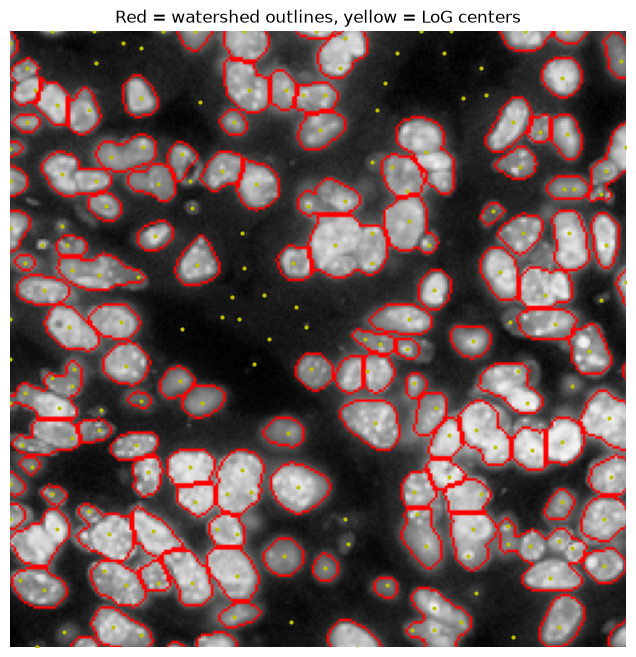

In [10]:
# For each LoG blob, which watershed region does its center fall in?
blob_regions = []
for y, x, s in blobs:
    blob_regions.append(ws[int(round(y)), int(round(x))])
blob_regions = np.array(blob_regions)

outside = np.sum(blob_regions == 0)
print(f"LoG blobs outside any watershed region (likely dim nuclei the mask missed): {outside}")

# How many LoG blobs does each watershed region contain?
ids, per_region = np.unique(blob_regions[blob_regions > 0], return_counts=True)
n_regions = len([r for r in measure.regionprops(ws) if r.area >= 30])
n_zero = n_regions - len(ids)
print(f"Watershed regions with 0 blobs: {n_zero}")
print(f"Watershed regions with exactly 1 blob: {np.sum(per_region == 1)}")
print(f"Watershed regions with 2+ blobs: {np.sum(per_region >= 2)}  "
      f"(under-split clumps, or one nucleus double-detected)")

# Visual: LoG centers (yellow) over watershed outlines (red); look at the ones that disagree
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(segmentation.mark_boundaries(img_disp, ws, color=(1, 0, 0)))
ax.plot(blobs[:, 1], blobs[:, 0], 'y.', ms=4)
ax.set_xlim(0, 250); ax.set_ylim(250, 0)           # zoom on a 250×250 crop
ax.set_title('Red = watershed outlines, yellow = LoG centers'); ax.axis('off')
plt.show()

In [11]:
print("Total blobs in this set:", len(blobs))

# Diagnostic with a consistent size filter
valid_ids = {r.label for r in measure.regionprops(ws) if r.area >= 30}
blob_regions = np.array([ws[int(round(y)), int(round(x))] for y, x, s in blobs])
inside = blob_regions[np.isin(blob_regions, list(valid_ids))]
ids, per_region = np.unique(inside, return_counts=True)
print("Outside any region      :", np.sum(~np.isin(blob_regions, list(valid_ids))))
print("Regions with 0 blobs    :", len(valid_ids) - len(ids))
print("Regions with 1 blob     :", np.sum(per_region == 1))
print("Regions with 2+ blobs   :", np.sum(per_region >= 2))

# Cleaner LoG: skip the texture-scale σ=3 and drop detections in the background
b = count_blobs(min_sigma=4, max_sigma=7, num_sigma=4, threshold=0.05)
in_mask = np.array([ws[int(round(y)), int(round(x))] > 0 for y, x, s in b])
print("LoG σ 4–7 raw          :", len(b))
print("LoG σ 4–7 inside mask  :", in_mask.sum())

Total blobs in this set: 1316
Outside any region      : 220
Regions with 0 blobs    : 15
Regions with 1 blob     : 555
Regions with 2+ blobs   : 215
LoG σ 4–7 raw          : 1003
LoG σ 4–7 inside mask  : 925


In [12]:
crop = [r for r in measure.regionprops(ws) if r.area >= 30
        and 0 <= r.centroid[1] < 250 and 0 <= r.centroid[0] < 250]
print("Watershed regions in crop:", len(crop))

Watershed regions in crop: 115
